# Analisis CSV Graf Jalan Dukuh Kupang

Notebook ini membaca `nodes.csv` dan `edges.csv` hasil command Go `analyze` untuk memeriksa struktur graf mentah, panjang segmen, dan empat atribut: **highway, surface, width, access**.

Satuan pengamatan utama adalah **edge terarah**, termasuk arah balik dan edge paralel. Jumlah edge tidak sama dengan jumlah ruas fisik unik. Graf belum disederhanakan, sehingga hasilnya belum dapat langsung disamakan dengan graf akhir proyek Python acuan.

Jalankan cell dari atas ke bawah. Sebelum memakai hasil untuk laporan, pilih **Restart Kernel and Run All** agar seluruh keluaran berasal dari pembacaan CSV yang sama.

## 1. Environment dan pilihan workdir

Buka notebook dari root repository menggunakan kernel **Running Route Analysis (Python 3.13)**. Ubah variabel `WORKDIR` pada cell berikut untuk memilih percobaan. `output_dir` dibaca dari YAML agar lokasi CSV mengikuti CLI.

Sebelum menjalankan notebook, perbarui CSV melalui terminal jika snapshot atau kode exporter berubah:

```bash
go run ./cmd/cli analyze --workdir workdirs/dukuh-kupang
```

Notebook memakai CSV yang sudah tersedia dan tidak melakukan pengambilan data OSM.

In [1]:
from pathlib import Path
import math
import sys

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "go.mod").is_file():
    raise RuntimeError("Open this notebook from the Go repository root.")
if Path(sys.prefix).resolve() != (ROOT / ".venv").resolve():
    raise RuntimeError("Select the Running Route Analysis (Python 3.13) kernel.")

# Change only this path to select another experiment.
WORKDIR = ROOT / "workdirs" / "dukuh-kupang"
config = yaml.safe_load((WORKDIR / "config.yaml").read_text())
OUTPUT_DIR = WORKDIR / (config.get("output_dir") or "output").strip()
ANALYSIS_DIR = OUTPUT_DIR / "analysis"
ATTRIBUTES = ["highway", "surface", "width", "access"]
TOP_N = 10

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
print("Python:", sys.version.split()[0])
print("Environment:", sys.prefix)
print("Workdir:", WORKDIR)
print("CSV directory:", OUTPUT_DIR)

Python: 3.13.16
Environment: /Users/david/development/go-running-route-q-learning/.venv
Workdir: /Users/david/development/go-running-route-q-learning/workdirs/dukuh-kupang
CSV directory: /Users/david/development/go-running-route-q-learning/workdirs/dukuh-kupang/output


## 2. Membaca CSV dan memeriksa konsistensi

ID dibaca sebagai integer 64 bit agar ID OSM yang besar tidak berubah menjadi angka pecahan. Atribut dibaca sebagai teks; string kosong tetap kosong. Dengan begitu, nilai width seperti `3`, `3 m`, dan `3;4` tetap dapat dibedakan.

Pemeriksaan berikut mendeteksi tabel kosong, ID duplikat, referensi node yang hilang, koordinat di luar rentang, serta panjang negatif atau non-finite. Ini pemeriksaan konsistensi CSV, bukan validasi kondisi jalan di lapangan.

In [2]:
NODE_COLUMNS = ["node_id", "latitude", "longitude"]
EDGE_COLUMNS = [
    "from", "to", "key", "way_id", "length_m", "name",
    "highway", "surface", "width", "access",
]
for filename in ("nodes.csv", "edges.csv"):
    if not (OUTPUT_DIR / filename).is_file():
        raise FileNotFoundError(f"Missing {filename}; run the Go analyze command for this workdir first.")

nodes = pd.read_csv(
    OUTPUT_DIR / "nodes.csv", usecols=NODE_COLUMNS,
    dtype={"node_id": "int64", "latitude": "float64", "longitude": "float64"},
    keep_default_na=False,
)
edges = pd.read_csv(
    OUTPUT_DIR / "edges.csv", usecols=EDGE_COLUMNS,
    dtype={
        "from": "int64", "to": "int64", "key": "int64", "way_id": "int64",
        "length_m": "float64", "name": "string",
        **{attribute: "string" for attribute in ATTRIBUTES},
    },
    keep_default_na=False,
)
print(f"Loaded {len(nodes):,} nodes and {len(edges):,} directed edges.")

Loaded 26,345 nodes and 58,020 directed edges.


In [4]:
finite_coordinates = nodes[["latitude", "longitude"]].map(math.isfinite).all(axis=1)
coordinates_in_range = nodes["latitude"].between(-90, 90) & nodes["longitude"].between(-180, 180)
finite_lengths = edges["length_m"].map(math.isfinite)
checks = pd.DataFrame([
    {"check": "Empty node table", "violations": int(nodes.empty)},
    {"check": "Empty edge table", "violations": int(edges.empty)},
    {"check": "Duplicate node IDs", "violations": int(nodes["node_id"].duplicated().sum())},
    {"check": "Duplicate (from, to, key)", "violations": int(edges.duplicated(["from", "to", "key"]).sum())},
    {"check": "Missing source nodes", "violations": int((~edges["from"].isin(nodes["node_id"])).sum())},
    {"check": "Missing destination nodes", "violations": int((~edges["to"].isin(nodes["node_id"])).sum())},
    {"check": "Invalid coordinates", "violations": int((~finite_coordinates | ~coordinates_in_range).sum())},
    {"check": "Invalid segment lengths", "violations": int((~finite_lengths | edges["length_m"].lt(0)).sum())},
])
display(checks)
if checks["violations"].gt(0).any():
    raise ValueError("CSV consistency checks failed. Inspect the table before continuing.")

,check,violations
0,Empty node table,0
1,Empty edge table,0
2,Duplicate node IDs,0
3,"Duplicate (from, to, key)",0
4,Missing source nodes,0
5,Missing destination nodes,0
6,Invalid coordinates,0
7,Invalid segment lengths,0


## 3. Sampel dan ringkasan graf

Sampel membantu mengenali isi setiap kolom sebelum membaca statistik. `way_id` adalah ID way OSM asal; `(from, to, key)` adalah identitas edge terarah.

Jumlah tujuan unik menghitung node tetangga, sehingga dua edge paralel menuju node yang sama tetap dihitung sebagai satu tujuan. Node dengan satu tujuan unik adalah ciri struktur graf; angka ini belum menyatakan terminasi buntu pada environment Q-learning.

In [5]:
print("Node sample")
display(nodes.head())
print("Directed edge sample")
display(edges.head())

unique_destinations = edges.groupby("from")["to"].nunique().reindex(nodes["node_id"], fill_value=0)
pair_sizes = edges.groupby(["from", "to"]).size()
summary = pd.DataFrame([
    {"metric": "Nodes", "value": len(nodes)},
    {"metric": "Directed edges", "value": len(edges)},
    {"metric": "Source OSM ways represented", "value": edges["way_id"].nunique()},
    {"metric": "Nodes without outgoing edges", "value": int(unique_destinations.eq(0).sum())},
    {"metric": "Nodes with one unique destination", "value": int(unique_destinations.eq(1).sum())},
    {"metric": "Directed node pairs with parallel edges", "value": int(pair_sizes.gt(1).sum())},
    {"metric": "Zero-length directed edges", "value": int(edges["length_m"].eq(0).sum())},
])
display(summary)

Node sample


,node_id,latitude,longitude
0,257690921,-7.258684,112.733157
1,264874793,-7.251185,112.736715
2,270391863,-7.250179,112.735845
3,270392236,-7.280663,112.731204
4,270392240,-7.270384,112.719350


Directed edge sample


,from,to,key,way_id,length_m,name,highway,surface,width,access
0,257690921,3556298311,0,24884734,13.046503,Jalan Kedungdoro,primary,asphalt,4,
1,257690921,3556298318,1,349838834,9.093768,,primary,asphalt,4,
2,257690921,4462723035,2,1026679598,95.797546,Jalan Kedungdoro,primary,asphalt,4,
3,264874793,6868863241,0,93865170,8.411364,Jalan Baliwerti,tertiary,asphalt,8,
4,270391863,1687336777,0,254757803,45.981900,Jalan Bubutan,primary,,,


,metric,value
0,Nodes,26345
1,Directed edges,58020
2,Source OSM ways represented,6742
3,Nodes without outgoing edges,0
4,Nodes with one unique destination,1927
5,Directed node pairs with parallel edges,0
6,Zero-length directed edges,0


## 4. Panjang segmen

Panjang dibaca dari hasil Haversine Go, bukan dihitung ulang di notebook. Statistik dan histogram memakai seluruh edge terarah. Baris `count` menyatakan jumlah edge; statistik lainnya dalam meter.

Segmen nol meter ditampilkan sebagai bagian kualitas data. Statistik ini belum menunjukkan panjang satu rute lari dan tidak dipakai untuk menyimpulkan keberhasilan target 5 km.

,statistic,value
0,count,58020.000000
1,mean,25.116473
2,std,31.775998
3,min,0.035135
4,25%,5.376600
5,50%,13.812988
6,75%,33.090935
7,95%,86.396205
8,99%,156.578252
9,max,418.737802


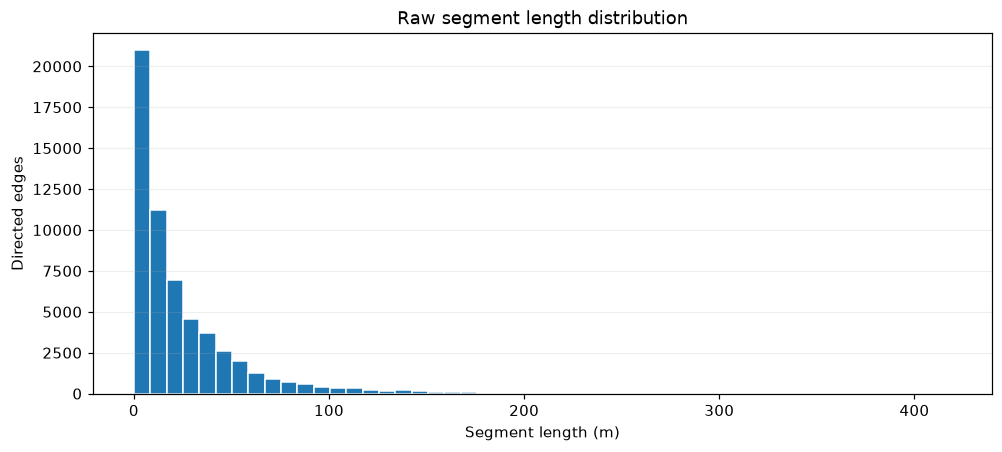

In [7]:
length_statistics = edges["length_m"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
length_statistics = length_statistics.rename_axis("statistic").reset_index(name="value")
display(length_statistics)

length_figure, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.hist(edges["length_m"], bins=50, color="tab:blue", edgecolor="white")
ax.set(title="Raw segment length distribution", xlabel="Segment length (m)", ylabel="Directed edges")
ax.grid(axis="y", alpha=0.2)
plt.show()

## 5. Kelengkapan empat atribut

Atribut dianggap terisi jika teksnya tidak kosong setelah whitespace di awal/akhir dihapus. Nilai mentah pada `edges` tetap dipertahankan; pemangkasan hanya dilakukan pada salinan analisis.

Persentase memakai jumlah seluruh edge terarah sebagai penyebut. **Terisi tidak berarti nilainya valid atau sesuai preferensi penelitian.** Khusus width, keterbacaan numeriknya diperiksa terpisah.

,attribute,present_edges,missing_edges,present_pct,missing_pct
0,highway,58020,0,100.00,0.00
1,surface,37082,20938,63.91,36.09
2,width,36544,21476,62.99,37.01
3,access,1652,56368,2.85,97.15


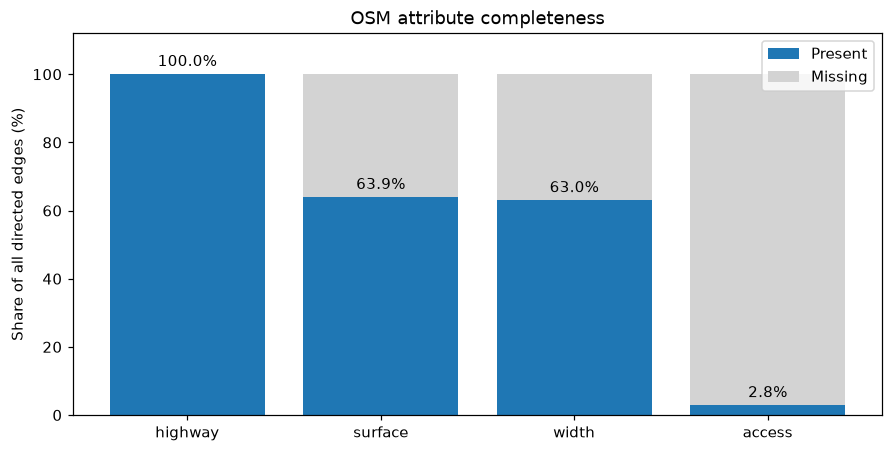

In [8]:
attribute_values = edges[ATTRIBUTES].apply(lambda column: column.str.strip())
edge_count = len(edges)
completeness = pd.DataFrame([
    {
        "attribute": attribute,
        "present_edges": int(attribute_values[attribute].ne("").sum()),
        "missing_edges": int(attribute_values[attribute].eq("").sum()),
    }
    for attribute in ATTRIBUTES
])
completeness["present_pct"] = completeness["present_edges"] / edge_count * 100
completeness["missing_pct"] = completeness["missing_edges"] / edge_count * 100
display(completeness.round(2))

completeness_figure, ax = plt.subplots(figsize=(8, 4), layout="constrained")
bars = ax.bar(completeness["attribute"], completeness["present_pct"], label="Present", color="tab:blue")
ax.bar(completeness["attribute"], completeness["missing_pct"], bottom=completeness["present_pct"], label="Missing", color="lightgray")
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in completeness["present_pct"]], padding=3)
ax.set(title="OSM attribute completeness", ylabel="Share of all directed edges (%)", ylim=(0, 112))
ax.legend(loc="upper right")
plt.show()

## 6. Distribusi highway, surface, width, dan access

Tabel dan diagram menampilkan maksimal `TOP_N` kategori terbesar per atribut, termasuk kategori kosong. Persentase tetap dihitung terhadap **semua edge**, bukan hanya kategori yang ditampilkan. Tabel lengkap disimpan pada langkah ekspor hasil.

Kapitalisasi dan nilai gabungan dipertahankan sebagai kategori asal. Tag access menunjukkan data sumber, bukan hasil keputusan legalitas action mask. Pada bagian ini tidak ada pemberian skor kenyamanan atau reward.

highway


,value,edge_count,percentage
0,residential,21012,36.22
1,living_street,17346,29.9
2,service,7744,13.35
3,tertiary,3558,6.13
4,secondary,2880,4.96
5,primary,1794,3.09
6,trunk,818,1.41
7,path,814,1.4
8,footway,742,1.28
9,secondary_link,408,0.7


surface


,value,edge_count,percentage
0,paving_stones,22116,38.12
1,(missing),20938,36.09
2,asphalt,13292,22.91
3,concrete,1472,2.54
4,ground,120,0.21
5,unpaved,34,0.06
6,gravel,24,0.04
7,paved,22,0.04
8,dirt,2,0.0


width


,value,edge_count,percentage
0,(missing),21476,37.01
1,2,9880,17.03
2,3,8696,14.99
3,4,7276,12.54
4,1,2522,4.35
5,6,2480,4.27
6,1.5,1384,2.39
7,2.5,1290,2.22
8,5,1200,2.07
9,8,670,1.15


access


,value,edge_count,percentage
0,(missing),56368,97.15
1,permissive,1014,1.75
2,yes,458,0.79
3,destination,138,0.24
4,no,42,0.07


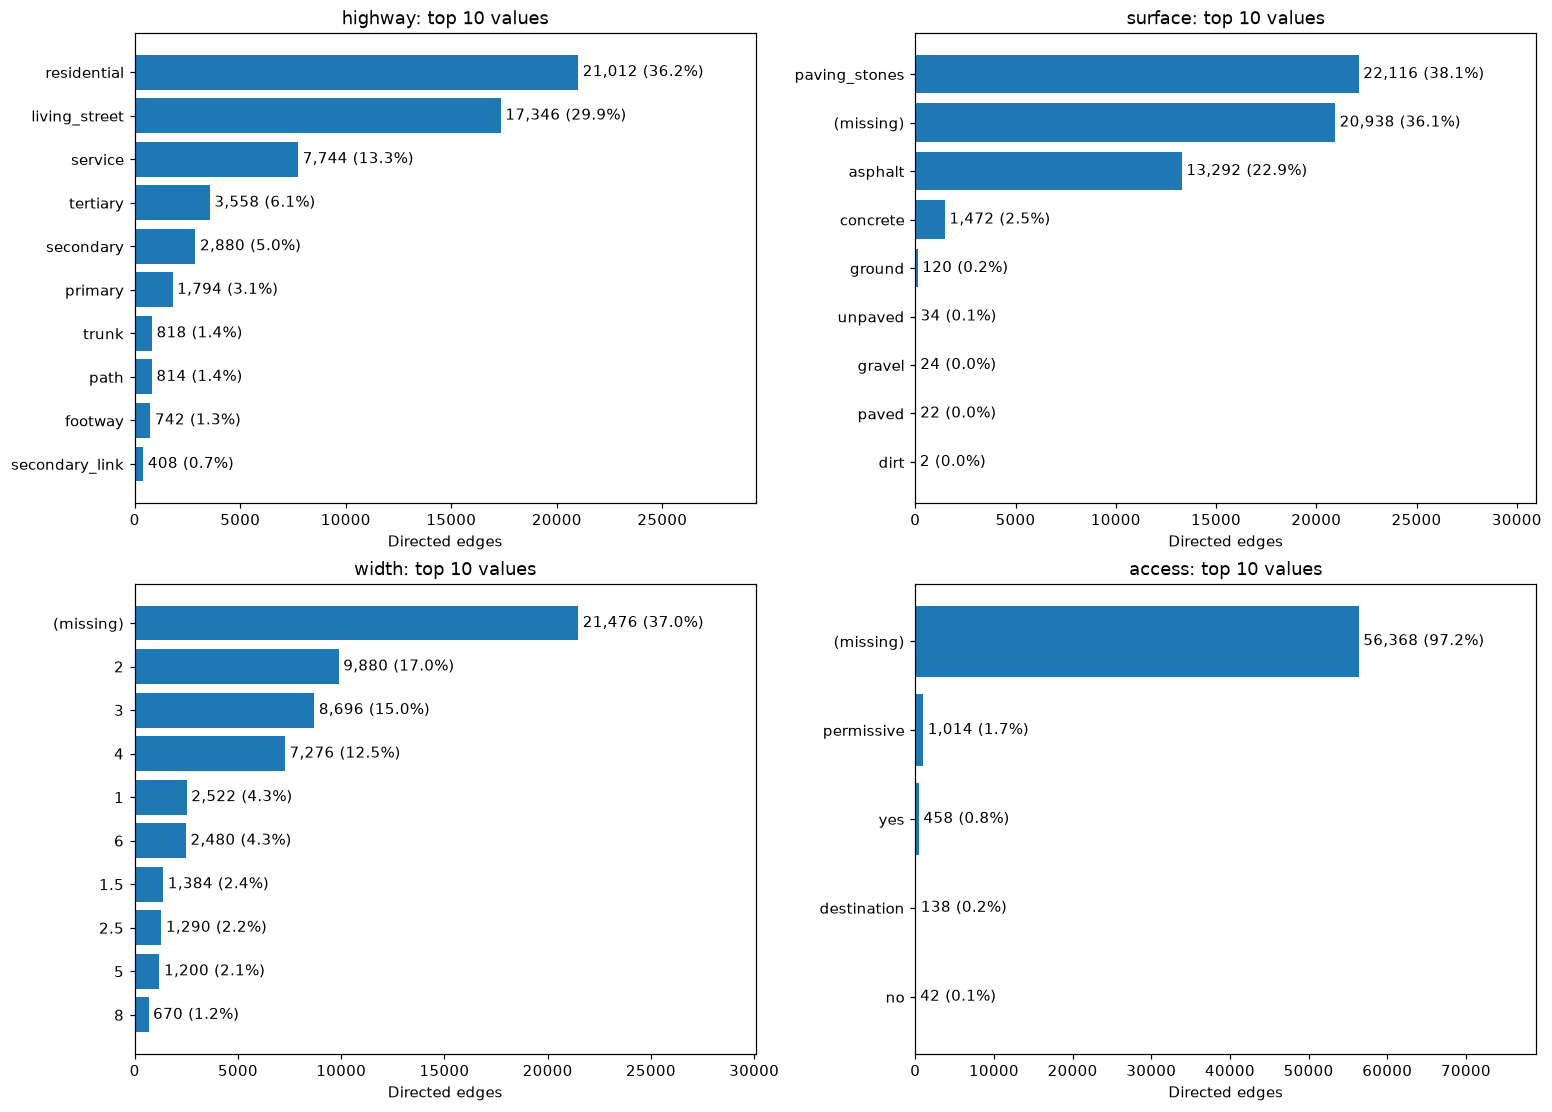

In [9]:
distributions = {}
for attribute in ATTRIBUTES:
    values = attribute_values[attribute].replace("", "(missing)")
    table = values.value_counts().rename_axis("value").reset_index(name="edge_count")
    table["percentage"] = table["edge_count"] / edge_count * 100
    distributions[attribute] = table
    print(attribute)
    display(table.head(TOP_N).round(2))

attributes_figure, axes = plt.subplots(2, 2, figsize=(14, 10), layout="constrained")
for ax, attribute in zip(axes.flat, ATTRIBUTES):
    table = distributions[attribute].head(TOP_N)
    bars = ax.barh(table["value"], table["edge_count"], color="tab:blue")
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f"{count:,} ({percentage:.1f}%)" for count, percentage in zip(table["edge_count"], table["percentage"])], padding=3)
    ax.set(title=f"{attribute}: top {TOP_N} values", xlabel="Directed edges")
    ax.margins(x=0.4)
plt.show()

## 7. Kualitas nilai width

Pemeriksaan ini memisahkan tag kosong, angka positif, serta nilai yang belum dapat dibaca sebagai angka atau tidak positif. Nilai bersatuan seperti `3 m` dan nilai gabungan seperti `3;4` tetap berada dalam kategori belum terurai; notebook tidak menebak atau mengonversinya.

Angka positif dibagi pada batas 3 meter agar mudah ditinjau terhadap preferensi penelitian pada proyek acuan. Batas ini bukan standar keselamatan atau hasil survei pelari. Klasifikasi berikut merupakan analisis data, bukan implementasi reward.

In [10]:
width_raw = attribute_values["width"]
width_numeric = pd.to_numeric(width_raw, errors="coerce")
positive_numeric_width = width_numeric.fillna(0).map(math.isfinite) & width_numeric.gt(0).fillna(False)
width_status = pd.Series("Unparsed or non-positive", index=edges.index, dtype="string")
width_status.loc[width_raw.eq("")] = "Missing"
width_status.loc[positive_numeric_width & width_numeric.lt(3).fillna(False)] = "Positive numeric <3 m"
width_status.loc[positive_numeric_width & width_numeric.ge(3).fillna(False)] = "Positive numeric >=3 m"
width_order = ["Missing", "Unparsed or non-positive", "Positive numeric <3 m", "Positive numeric >=3 m"]
width_quality = width_status.value_counts().reindex(width_order, fill_value=0).rename_axis("category").reset_index(name="edge_count")
width_quality["percentage"] = width_quality["edge_count"] / edge_count * 100
display(width_quality.round(2))

print("Examples of non-empty width values not parsed as a positive number")
display(width_raw.loc[width_raw.ne("") & ~positive_numeric_width].value_counts().head(TOP_N).rename_axis("raw_width").reset_index(name="edge_count"))

,category,edge_count,percentage
0,Missing,21476,37.01
1,Unparsed or non-positive,0,0.0
2,Positive numeric <3 m,15268,26.32
3,Positive numeric >=3 m,21276,36.67


Examples of non-empty width values not parsed as a positive number


,raw_width,edge_count


## 8. Kombinasi ketersediaan atribut

Tabel ini menunjukkan atribut mana yang tersedia bersama pada satu edge. `True` berarti terisi dan `False` berarti kosong. Empat atribut memiliki paling banyak 16 kombinasi. Nilai di dalam atribut belum dinilai melalui tabel ini.

In [11]:
combinations = attribute_values.ne("").value_counts().rename("edge_count").reset_index()
combinations["percentage"] = combinations["edge_count"] / edge_count * 100
display(combinations.round(2))

,highway,surface,width,access,edge_count,percentage
0,True,True,True,False,34756,59.90
1,True,False,False,False,20102,34.65
2,True,True,True,True,1286,2.22
3,True,True,False,False,1008,1.74
4,True,False,True,False,502,0.87
5,True,False,False,True,334,0.58
6,True,True,False,True,32,0.06


## 9. Menyimpan tabel dan diagram

Cell ini menulis ulang hasil analisis ke `output_dir/analysis/` dalam workdir yang dipilih. CSV input tetap dipertahankan. Nama file tetap agar hasil dari eksekusi berikutnya menggantikan file yang sama.

Grafik berisi seluruh edge untuk histogram/kelengkapan, sedangkan diagram kategori menampilkan `TOP_N`. Distribusi kategori lengkap tetap tersedia dalam `attribute_distributions.csv`.

In [12]:
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
all_distributions = pd.concat(
    [table.assign(attribute=attribute) for attribute, table in distributions.items()],
    ignore_index=True,
)[["attribute", "value", "edge_count", "percentage"]]
tables = {
    "graph_summary.csv": summary,
    "segment_length_statistics.csv": length_statistics,
    "attribute_completeness.csv": completeness,
    "attribute_distributions.csv": all_distributions,
    "width_quality.csv": width_quality,
    "attribute_availability_combinations.csv": combinations,
}
for filename, table in tables.items():
    table.to_csv(ANALYSIS_DIR / filename, index=False)

figures = {
    "segment_lengths.png": length_figure,
    "attribute_completeness.png": completeness_figure,
    "attribute_distributions.png": attributes_figure,
}
for filename, figure in figures.items():
    figure.savefig(ANALYSIS_DIR / filename, dpi=180, bbox_inches="tight")

print("Analysis files:", ANALYSIS_DIR)
for filename in [*tables, *figures]:
    print("-", filename)

Analysis files: /Users/david/development/go-running-route-q-learning/workdirs/dukuh-kupang/output/analysis
- graph_summary.csv
- segment_length_statistics.csv
- attribute_completeness.csv
- attribute_distributions.csv
- width_quality.csv
- attribute_availability_combinations.csv
- segment_lengths.png
- attribute_completeness.png
- attribute_distributions.png


## Cara membaca hasil

- Semua persentase utama di atas memakai **edge terarah**, termasuk arah balik. Jangan mencampurkan jumlah edge dengan jumlah way atau ruas fisik unik.
- Tag kosong menunjukkan informasi yang tidak tersedia pada CSV. Kelengkapan tinggi belum menyatakan jalan lebih nyaman atau lebih aman.
- Distribusi panjang menggambarkan segmen graf mentah, bukan hasil rute atau keberhasilan training.
- Catat workdir dan simpan snapshot beserta CSV yang dipakai untuk hasil laporan. Path hasil yang sama akan ditimpa ketika command atau notebook dijalankan ulang.
- Analisis peta, perhitungan reward, dan hasil training dilanjutkan pada tahap komponennya masing-masing.

Rujukan implementasi sumber data: [exporter CSV](internal/osm/csv.go), [pembentukan graf](internal/osm/graph.go), dan [panduan penggunaan proyek](README.md).